# Л1 — Підготовка даних

Велика частина роботи в Data Science — збір і підготовка даних. Саме тут виникає багато неочікуваних проблем і пасток.

Ноутбук нижче базово показує, як працювати з даними й готувати їх. Він не охоплює всіх можливих сценаріїв, а приклади в ньому часом сильно спрощені. Проте він дасть розуміння, де шукати помилки і як з ними боротися. Більше туторіалів — у [Kaggle Learn](https://www.kaggle.com/learn), зокрема [Data Cleaning](https://www.kaggle.com/learn/data-cleaning).

Базовий алгоритм підготовки даних може виглядати так (у дужках — кроки цього ноутбука):

- зчитування даних і початкове дослідження (1);
- дослідження структури й особливостей даних, зміна типів (2);
- об'єднання даних з різних джерел (3–4);
- робота з пропущеними й зламаними значеннями: drop, fill тощо (5, 7, 8);
- пошук outliers: drop, clip тощо (6);
- пошук зайвих і бракуючих колонок (9).

І головне: з кожною дією треба бути обережним. Outliers можуть бути реальними даними, які логічно пояснюються і які не можна видаляти. А пропущені значення можуть щось означати й бути корисними. Обидва випадки є в цій роботі.

Далі бувають кроки, специфічні для певних моделей чи алгоритмів:

- scaling: normalization, standardization тощо;
- обробка категорійних колонок: one-hot encoding тощо;
- dimensionality reduction.

Тут вони не розглядаються, частину з них побачите в Л2 і Л3.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних і таблиця недоліків — у `README.md`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

## 1. Завантаження даних

На цьому етапі важливо впевнитися, що файли завантажено правильно, і подивитися, що взагалі всередині. Можуть допомогти `df.head()`, `df.tail()`, `df.shape` і `df.dtypes`.

Що ви маєте зрозуміти?

- Чи зчиталися дані взагалі?
- Чи правильно розпарсилися рядки, колонки й значення?
- Які типи в колонок?
- Які приблизно значення?
- Скільки рядків і колонок?

In [2]:
dfm = pd.read_parquet('data/meters.parquet')
dfr = pd.read_csv('data/registry.csv')

print('Meters overview:', '\n')
print(dfm.dtypes, '\n')
print(dfm.describe(), '\n')

print('Registry overview:', '\n')
print(dfr.dtypes, '\n')
print(dfr.describe(), '\n')

dfr.head()

Meters overview: 

meter_id                      str
ts                 datetime64[us]
consumption_kwh           float64
record_ts          datetime64[us]
dtype: object 

                               ts  consumption_kwh                   record_ts
count                      526392    526392.000000                      526392
mean   2026-01-18 18:38:47.875803       727.578367  2026-01-18 19:01:12.689330
min           2026-01-05 00:00:00         0.025600         2026-01-05 00:01:00
25%           2026-01-11 19:00:00         0.436900         2026-01-11 19:14:11
50%           2026-01-18 15:00:00         0.922200  2026-01-18 16:03:36.500000
75%           2026-01-25 17:00:00         2.774300  2026-01-25 18:01:10.250000
max           2026-02-01 23:00:00    383213.600000         2026-02-02 22:25:34
std                           NaN      8162.577631                         NaN 

Registry overview: 

meter_id              str
customer_type         str
tariff                str
electric_heating 

,meter_id,customer_type,tariff,electric_heating,connection_year,years_connected,district
0,UA101445,household,dual_zone,1,2021,5,Sviatoshyn
1,UA101459,small_business,single,0,2003,23,Solomianka
2,UA101761,household,dual_zone,1,2002,23,Sviatoshyn
3,UA101991,small_business,single,0,1997,29,Solomianka
4,UA104014,household,single,0,2022,4,Darnytsia


## 2. Звірка з описом

Іноді бізнес надає опис ідеальних даних, але реальні дані часто з ним не збігаються. Тому спершу подивіться, чи ваші дані відповідають опису в `README.md`. Може допомогти `df.describe()`.

Перевірте (але поки не виправляйте):

- типи колонок: якщо число прочиталося як текст, частина операцій спрацює неправильно;
- скільки рядків мають `customer_type`, `tariff` чи `electric_heating`, яких немає в описі;
- скільки рядків мають `ts`, `connection_year` чи `years_connected` поза межами з опису;
- скільки різних лічильників у кожному файлі — мають бути по 800.

Можуть допомогти `isin`, `between` і `nunique`.

Недоліки з таблиці в `README.md` перевірятимете далі, кожен у своєму кроці. Межі споживання залежать від типу абонента, а тип є лише в реєстрі, тому їх перевірите після об'єднання, на кроці 6.

In [3]:
bad_type = ~dfr["customer_type"].isin(["household", "small_business", "industrial"])
print("customer_type поза описом:", bad_type.sum(), dfr.loc[bad_type, "customer_type"].unique())

bad_tariff = ~dfr["tariff"].isin(["single", "dual_zone"])
print("tariff поза описом:", bad_tariff.sum(), dfr.loc[bad_tariff, "tariff"].unique())

bad_heat = ~dfr["electric_heating"].isin([0, 1])
print("electric_heating поза описом:", bad_heat.sum(), dfr.loc[bad_heat, "electric_heating"].unique())

bad_ts = ~dfm["ts"].between("2026-01-05 00:00", "2026-02-01 23:00")
print("ts поза межами:", bad_ts.sum())

bad_year = ~dfr["connection_year"].between(1985, 2024)
print("connection_year поза межами:", bad_year.sum())

bad_years = ~dfr["years_connected"].between(1, 41)
print("years_connected поза межами:", bad_years.sum())

print("лічильників у meters:", dfm["meter_id"].nunique())
print("лічильників у registry:", dfr["meter_id"].nunique())

customer_type поза описом: 0 <ArrowStringArray>
[]
Length: 0, dtype: str
tariff поза описом: 0 <ArrowStringArray>
[]
Length: 0, dtype: str
electric_heating поза описом: 0 []
ts поза межами: 0
connection_year поза межами: 0
years_connected поза межами: 0
лічильників у meters: 800
лічильників у registry: 800


## 3. Реєстр: номери й райони (D-E, D-F)

Дані зберігаються в різних системах, тому формат ідентифікатора може не збігатися: `" UA123456"` для pandas — інший номер, ніж `UA123456`. Наївний join призведе до того, що частина даних втратиться. Так само `podil` і `Podil` — різні райони, і будь-який підрахунок по районах буде хибним.

Для D-E і D-F виведіть, скільки рядків реєстру зіпсовано, і виправте їх так, як сказано в таблиці недоліків. Можуть допомогти `str.fullmatch(r"UA\d{6}")`, `isin`, `str.strip()`, `str.lstrip("0")` і `str.capitalize()`.

In [4]:
# D-E
ok_id = dfr["meter_id"].str.fullmatch(r"UA\d{6}")
print("зіпсованих номерів:", (~ok_id).sum())

dfr["meter_id"] = dfr["meter_id"].str.strip().str.lstrip("0")
print("після виправлення:", (~dfr["meter_id"].str.fullmatch(r"UA\d{6}")).sum())

# D-F 
districts = ["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"]
bad_d = ~dfr["district"].isin(districts)
print("районів не як в описі:", bad_d.sum(), dfr.loc[bad_d, "district"].unique())

dfr["district"] = dfr["district"].str.strip().str.capitalize()
print("після виправлення:", (~dfr["district"].isin(districts)).sum())


зіпсованих номерів: 0
після виправлення: 0
районів не як в описі: 80 <ArrowStringArray>
[     'OBOLON',  'Darnytsia ', 'Solomianka ',       'PODIL',  'sviatoshyn',
   'darnytsia',      'Podil ',       'podil', 'Sviatoshyn ',  'solomianka',
      'obolon',     'Obolon ',  'SOLOMIANKA',  'SVIATOSHYN',   'DARNYTSIA']
Length: 15, dtype: str
після виправлення: 0


## 4. Об'єднання

Тепер погодинні дані можна об'єднати з реєстром за `meter_id` (join, у pandas — `merge`). pandas не попереджає, коли рядок не знайшов пари, тому якість об'єднання треба перевірити самому.

Об'єднану таблицю назвіть `df`, з нею працюватимете далі. Перевірте й виведіть:

- кількість рядків до і після об'єднання — вона не має змінитися;
- кількість рядків без атрибутів абонента (пропуск у `customer_type`) — має бути 0.

Може допомогти `merge(..., how="left", validate="m:1")`: `validate` ще й перевірить, що кожному лічильнику відповідає один рядок реєстру.

In [5]:
df = dfm.merge(dfr, on="meter_id", how="left", validate="m:1")

print("рядків до:", len(dfm), "після:", len(df))
print("без атрибутів абонента:", df["customer_type"].isna().sum())


рядків до: 526392 після: 526392
без атрибутів абонента: 0


## 5. Повторні відправки (D-C)

Повторна відправка — та сама година того самого лічильника ще раз, іноді з уточненим значенням. Якщо лишити обидва записи, споживання за цю годину подвоїться. Лишаємо найпізніший за `record_ts` запис як найсвіжіший.

Виведіть кількість рядків і кількість різних пар `meter_id` і `ts`, потім зніміть повтори. Можуть допомогти `duplicated(["meter_id", "ts"])`, `sort_values("record_ts")` і `drop_duplicates(["meter_id", "ts"], keep="last")`.

In [6]:
# D-C
print("рядків:", len(df))
print("різних пар meter_id і ts:", len(df.drop_duplicates(["meter_id", "ts"])))

df = df.sort_values("record_ts").drop_duplicates(["meter_id", "ts"], keep="last")
print("після зняття повторів:", len(df))

рядків: 526392
різних пар meter_id і ts: 516183
після зняття повторів: 516183


## 6. Одиниці виміру (D-D)

Значення у Вт·год схожі на викиди, але це не шум, а помилка одиниць. Якщо їх видалити, зникнуть цілі абоненти.

1. Для кожного лічильника порахуйте відношення його медіани `consumption_kwh` до медіани всіх рядків його `customer_type`. Більше 100 — лічильник звітує у Вт·год.
2. Побудуйте графік медіан лічильників за `customer_type` з логарифмічною віссю, наприклад boxplot.
3. Виведіть кількість лічильників у Вт·год, найбільше відношення серед решти лічильників і найменше серед лічильників у Вт·год (якщо таких немає — лише найбільше відношення серед усіх). Ці числа — доказ у звіті: вони показують, наскільки далеко від порога обидві групи.
4. Поділіть значення цих лічильників на 1000 і виведіть, скільки рядків поза межами споживання з опису, — має бути 0.

Можуть допомогти `DataFrame.boxplot(column=..., by="customer_type")`, `plt.yscale("log")` і `between`. Клітинку з діленням не запускайте двічі: значення поділяться ще раз. Якщо так сталося, перезапустіть ноутбук з початку.

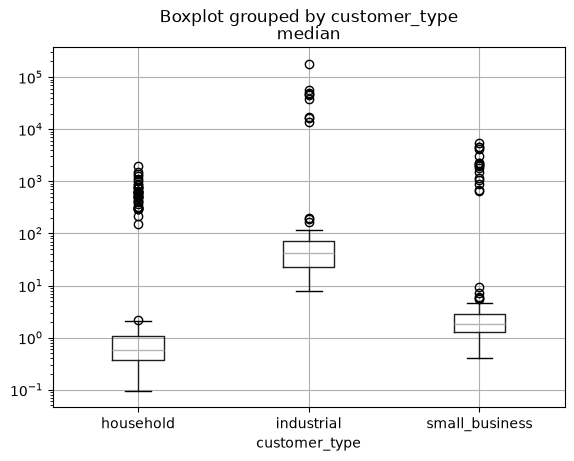

лічильників у Вт·год: 64
найбільше відношення серед решти: 5.0880820237498
найменше серед Вт·год: 237.0844388949586
поза межами споживання: 0


In [7]:
# D-D
meter_median = df.groupby("meter_id")["consumption_kwh"].median()
meter_type = df.groupby("meter_id")["customer_type"].first()
type_median = df.groupby("customer_type")["consumption_kwh"].median()
ratio = meter_median / meter_type.map(type_median)

plot_df = pd.DataFrame({"median": meter_median, "customer_type": meter_type})
plot_df.boxplot(column="median", by="customer_type")
plt.yscale("log")
plt.show()

wh = ratio[ratio > 100].index

print("лічильників у Вт·год:", len(wh))
print("найбільше відношення серед решти:", ratio[ratio <= 100].max())
print("найменше серед Вт·год:", ratio[ratio > 100].min())

df.loc[df["meter_id"].isin(wh), "consumption_kwh"] /= 1000

min_kwh = {"household": 0.01, "small_business": 0.02, "industrial": 1}
max_kwh = {"household": 10, "small_business": 60, "industrial": 1200}
out = ~df["consumption_kwh"].between(df["customer_type"].map(min_kwh), df["customer_type"].map(max_kwh))
print("поза межами споживання:", out.sum())


## 7. Лічильники, що замовкли (D-A)

Пропуски не заповнюємо: те, що лічильник замовк, уже є інформацією про можливу відмову, а середнє її стерло б. Не видаляємо теж: до відмови лічильник передавав правильні дані.

Для кожного лічильника порахуйте, скільки годин минуло від його останнього `ts` до `2026-02-01 23:00`; більше 48 — замовк. Як на кроці 6, виведіть кількість замовклих, найбільшу тишу серед решти й найменшу серед замовклих (якщо замовклих немає — лише найбільшу тишу серед усіх).

Номери замовклих лічильників збережіть списком `silent`, наприклад `list(....index)`: він знадобиться в регресії.

Можуть допомогти `pd.Timestamp("2026-02-01 23:00")` і `/ pd.Timedelta(hours=1)`.

In [8]:
# D-A
last_ts = df.groupby("meter_id")["ts"].max()
silence = (pd.Timestamp("2026-02-01 23:00") - last_ts) / pd.Timedelta(hours=1)

silent = list(silence[silence > 48].index)
print("замовклих:", len(silent))
print("найбільша тиша серед решти:", silence[silence <= 48].max())
print("найменша серед замовклих:", silence[silence > 48].min())


замовклих: 48
найбільша тиша серед решти: 1.0
найменша серед замовклих: 147.0


## 8. Завмерлі лічильники (D-B)

Завмерлі значення виглядають правдоподібно, і ні середнє, ні максимум їх не видають. Помітно лише те, що значення перестали змінюватися. Такі лічильники не видаляємо: частина їхніх годин справна.

Для кожного лічильника порахуйте частку різних значень `consumption_kwh` серед його записів; менше 0.65 — завмер. Побудуйте гістограму цієї частки по лічильниках. Як на кроці 6, виведіть кількість завмерлих, найменшу частку серед решти й найбільшу серед завмерлих (якщо завмерлих немає — лише найменшу частку серед усіх).

Номери завмерлих лічильників збережіть списком `frozen`: він знадобиться в регресії.

Можуть допомогти `nunique()`, `size()` і `plt.hist`.

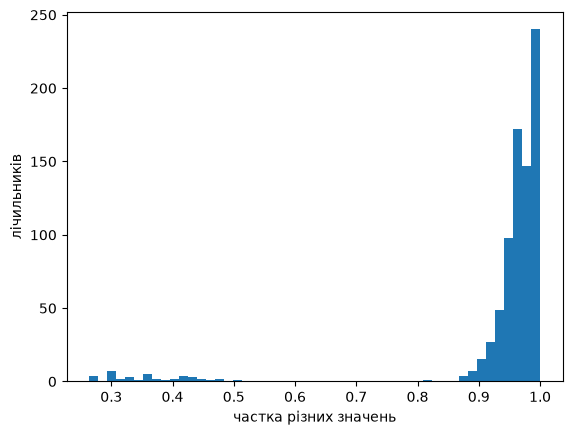

завмерлих: 40
найменша частка серед решти: 0.8163884673748103
найбільша серед завмерлих: 0.5075301204819277


In [9]:
# D-B
g = df.groupby("meter_id")["consumption_kwh"]
share = g.nunique() / g.size()

plt.hist(share, bins=50)
plt.xlabel("частка різних значень")
plt.ylabel("лічильників")
plt.show()

frozen = list(share[share < 0.65].index)
print("завмерлих:", len(frozen))
print("найменша частка серед решти:", share[share >= 0.65].min())
print("найбільша серед завмерлих:", share[share < 0.65].max())

## 9. Кореляції

Колонка, що майже копіює іншу, не додає інформації: у кластеризації вона подвоює вагу того самого фактора, а в регресії робить коефіцієнти нестабільними. Технічна колонка `record_ts` після кроку 5 теж не потрібна.

Порахуйте кореляції між числовими колонками об'єднаної таблиці. Пару з кореляцією за модулем понад 0.95 вважайте копією і лиште з неї одну колонку. Приберіть `record_ts`. Підсумкову таблицю назвіть `result`.

Можуть допомогти `select_dtypes("number").corr().abs()` і `drop(columns=...)`.

In [10]:
# TODO: знайдіть і приберіть колонку-копію та record_ts
corr = df.select_dtypes("number").corr().abs()
print(corr.round(3))

result = df.drop(columns=["years_connected", "record_ts"])

                  consumption_kwh  electric_heating  connection_year  \
consumption_kwh             1.000             0.096            0.051   
electric_heating            0.096             1.000            0.007   
connection_year             0.051             0.007            1.000   
years_connected             0.055             0.007            0.999   

                  years_connected  
consumption_kwh             0.055  
electric_heating            0.007  
connection_year             0.999  
years_connected             1.000  


## 10. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [11]:
districts = ["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"]
min_kwh = {"household": 0.01, "small_business": 0.02, "industrial": 1}
max_kwh = {"household": 10, "small_business": 60, "industrial": 1200}
corr = result.select_dtypes("number").corr().abs()
copies = [(a, b) for a in corr for b in corr if a < b and corr.loc[a, b] > 0.95]

assert not result.duplicated(["meter_id", "ts"]).any(), "лишилися повтори лічильник–година"
assert result["meter_id"].nunique() == 800, "лічильників має бути 800"
assert result["meter_id"].str.fullmatch(r"UA\d{6}").all(), "є номери не у форматі UA і 6 цифр"
assert result["customer_type"].notna().all(), "є рядки без атрибутів абонента"
assert result["district"].isin(districts).all(), "є райони, яких немає в описі"
assert result["consumption_kwh"].between(result["customer_type"].map(min_kwh), result["customer_type"].map(max_kwh)).all(), "є споживання поза межами з опису"
assert not copies, f"лишилися колонки-копії: {copies}"
assert "record_ts" not in result, "технічна колонка record_ts лишилася"

result.to_parquet("cleaned.parquet", index=False)
print("усе гаразд:", result.shape)

усе гаразд: (516183, 8)


## 11. Регресія

Регресію часто використовують, щоб передбачати певні показники. Проте лінійна регресія також показує, як кожен показник впливає на результат. Це і є регресійний аналіз.

Для прикладу подивимося, як на добове споживання домогосподарства впливають електроопалення і двозонний тариф: `y = a + b₁·x₁ + b₂·x₂`.

- `y` — середнє споживання лічильника за добу, кВт·год;
- `x₁` — `electric_heating`, `x₂` — двозонний тариф (обидва 0 або 1);
- `b₁` і `b₂` — на скільки кВт·год на добу більше споживає абонент із цим фактором за однакового іншого;
- `a` — споживання без опалення на звичайному тарифі;
- R² — яку частку розкиду споживання пояснюють обидва фактори, від 0 до 1.

Регресія тут краща за просте порівняння середніх: двозонний тариф здебільшого мають будинки з опаленням, і різниця середніх за тарифом приписала б тарифу ще й споживання на опалення.

Нормалізація не потрібна: обидва фактори мають однаковий масштаб (0 або 1), тож `b₁` і `b₂` можна порівнювати напряму, а `y` лишається в кВт·год на добу, і коефіцієнти легко пояснити. Якби фактори мали різні одиниці, наприклад площу і рік, для порівняння впливу їх спершу стандартизували б.

Лічильники з `silent` і `frozen` не беремо: у `cleaned.parquet` вони лишаються, але їхнє середнє споживання спотворене.

Код майже готовий: допишіть `homes` і запустіть.

In [12]:
# TODO: homes — рядки result для домогосподарств без лічильників із silent і frozen
# кожну умову беріть у дужки: result[(умова 1) & ~(умова 2)]
homes = result[(result["customer_type"] == "household") & ~(result["meter_id"].isin(silent + frozen))]

per_meter = homes.groupby("meter_id").agg(
    kwh_per_day=("consumption_kwh", "mean"),
    electric_heating=("electric_heating", "first"),
    tariff=("tariff", "first"),
)
per_meter["kwh_per_day"] *= 24
per_meter["dual_zone"] = (per_meter["tariff"] == "dual_zone").astype(int)

x, y = per_meter[["electric_heating", "dual_zone"]], per_meter["kwh_per_day"]
model = LinearRegression().fit(x, y)
print("лічильників:", len(per_meter))
print(f"a = {model.intercept_:.2f}, b₁ (опалення) = {model.coef_[0]:.2f}, b₂ (двозонний тариф) = {model.coef_[1]:.2f}, R² = {model.score(x, y):.3f}")

лічильників: 458
a = 11.74, b₁ (опалення) = 15.93, b₂ (двозонний тариф) = 3.98, R² = 0.621
